**Name:** Francis Reuben R
**USN:** 1RUA25CSE0168
**Section:** G
**Experiment:** 5
**Title:** Implementation of Linear Regression using Python

Predict weight from height, then fit the same line with gradient descent. The assignment then predicts food delivery time from distance, preparation time, traffic, and weather.

## Implementation of Linear regression using python

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
from IPython.display import Image, display

figures = Path("figures")
figures.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

## Load the dataset

In [2]:
DF1 = pd.read_csv("weight-height.csv")
DF2 = pd.read_csv("Food_Delivery_Times.csv")
print("weight-height", DF1.shape)
print("food delivery", DF2.shape)
DF1.head()

weight-height (10000, 3)
food delivery (1000, 9)


,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [3]:
print("weight-height nulls")
print(DF1.isnull().sum().to_string())
print()
print("food delivery nulls")
print(DF2.isnull().sum().to_string())
DF2.head()

weight-height nulls
Gender    0
Height    0
Weight    0

food delivery nulls
Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


### Standardize numerical features

Height is in inches and weight is in pounds. Three rows have a height above 90 inches (about 165 to 173 inches). Those values are not human heights, and a min-max scaler would treat 172.8 inches as the top of the range and squeeze everyone else. Those three rows are dropped. The heavy weights (about 250 to 270 pounds) sit on heights of 75 to 79 inches, so they stay.

In [4]:
bad_height = DF1["Height"] > 90
print("rows with height > 90 inches:", int(bad_height.sum()))
print(DF1.loc[bad_height, ["Gender", "Height", "Weight"]].to_string(index=False))
DF1 = DF1.loc[~bad_height].copy()
print("rows kept:", len(DF1))

feature_cols = ["Height", "Weight"]
scaler = MinMaxScaler()
DF1[feature_cols] = scaler.fit_transform(DF1[feature_cols])
print("scaler minimum (inches, pounds):", scaler.data_min_)
print("scaler maximum (inches, pounds):", scaler.data_max_)
DF1.head()

rows with height > 90 inches: 3
Gender     Height     Weight
  Male 172.800844 206.828189
  Male 164.731926 177.549263
Female 169.034243 163.852461
rows kept: 9997
scaler minimum (inches, pounds): [54.26313333 64.70012671]
scaler maximum (inches, pounds): [ 78.99874235 269.9896985 ]


,Gender,Height,Weight
0,Male,0.791728,0.863139
1,Male,0.586958,0.475476
2,Male,0.802364,0.721131
3,Male,0.706182,0.756699
4,Male,0.631424,0.689999


## Prepare dependant and independant variables

In [5]:
X = DF1[["Height"]]
Y = DF1["Weight"]
print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("Pearson r (scaled height, scaled weight):", round(float(X["Height"].corr(Y)), 4))

X shape: (9997, 1)
Y shape: (9997,)
Pearson r (scaled height, scaled weight): 0.9248


## Split the data into training and test set

In [6]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=67)
print("train:", len(X_train), "test:", len(X_test))

train: 7997 test: 2000


In [7]:
# Create a linear regression model
model = LinearRegression()

Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

## Training the linear regression model

In [8]:
model.fit(X_train, Y_train)
print("scaled slope:", round(float(model.coef_[0]), 4))
print("scaled intercept:", round(float(model.intercept_), 4))

scaled slope: 0.9284
scaled intercept: 0.0174


## Calculating the Mean Squared Error (MSE) and R-squared (R2)

In [9]:
Y_pred = model.predict(X_test)
mse = mean_squared_error(Y_test, Y_pred)
rmse = mse ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)
print("scaled test MSE:", round(mse, 6))
print("scaled test RMSE:", round(rmse, 6))
print("scaled test MAE:", round(mae, 6))
print("scaled test R2:", round(r2, 4))

# Inverse-transform weight only. Height is passed through so the scaler can undo both columns.
height_te = X_test["Height"].to_numpy()
pair_true = np.column_stack([height_te, Y_test.to_numpy()])
pair_pred = np.column_stack([height_te, Y_pred])
y_lb = scaler.inverse_transform(pair_true)[:, 1]
pred_lb = scaler.inverse_transform(pair_pred)[:, 1]
print("test MAE in pounds:", round(float(mean_absolute_error(y_lb, pred_lb)), 2))
print("test RMSE in pounds:", round(float(mean_squared_error(y_lb, pred_lb) ** 0.5), 2))
print("test R2 in pounds:", round(float(r2_score(y_lb, pred_lb)), 4))

scaled test MSE: 0.003624
scaled test RMSE: 0.060202
scaled test MAE: 0.048272
scaled test R2: 0.8531
test MAE in pounds: 9.91
test RMSE in pounds: 12.36
test R2 in pounds: 0.8531


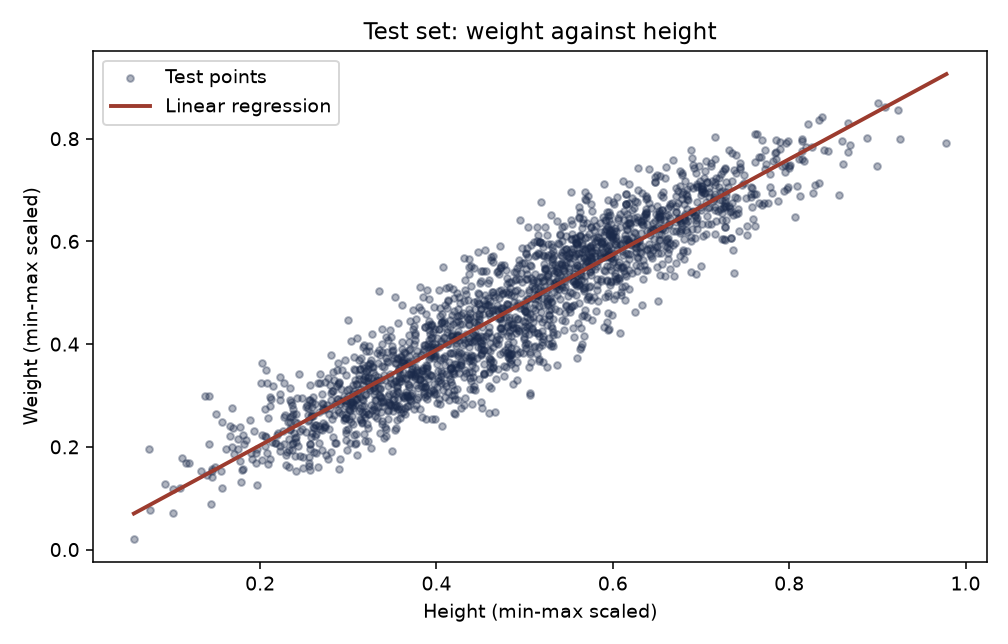

In [10]:
order = np.argsort(X_test["Height"].to_numpy())
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.scatter(X_test["Height"], Y_test, s=12, alpha=0.35, color="#1B2A4A", label="Test points")
ax.plot(
    X_test["Height"].to_numpy()[order],
    Y_pred[order],
    color="#9C3B2E",
    linewidth=2,
    label="Linear regression",
)
ax.set_xlabel("Height (min-max scaled)")
ax.set_ylabel("Weight (min-max scaled)")
ax.set_title("Test set: weight against height")
ax.legend()
fig.tight_layout()
plot_path = figures / "height_weight_fit.png"
fig.savefig(plot_path, dpi=140)
plt.close(fig)
display(Image(filename=str(plot_path)))

## Gradient descent from scratch

The line above is the normal equation inside `LinearRegression`. This section fits the same height-to-weight relation by gradient descent on z-scored values, using the cleaned table rather than the min-max scaled one.

The model is `y = theta0 + theta1 * x`. A column of ones carries the bias `theta0`.

In [11]:
raw = pd.read_csv("weight-height.csv")
raw = raw.loc[raw["Height"] <= 90].copy()
X = raw[["Height"]].to_numpy()
Y = raw[["Weight"]].to_numpy()
print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (9997, 1)
Y shape: (9997, 1)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

After both columns are z-scored, the slope equals the Pearson correlation and the intercept is 0.

In [12]:
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)
print("X mean, std:", round(float(X.mean()), 6), round(float(X.std()), 6))
print("Y mean, std:", round(float(Y.mean()), 6), round(float(Y.std()), 6))

X mean, std: -0.0 1.0
Y mean, std: -0.0 1.0


In [13]:
# Column of ones for the bias term
X = np.hstack((np.ones((X.shape[0], 1)), X))
print("X shape with bias:", X.shape)

X shape with bias: (9997, 2)


In [14]:
m = X.shape[0]
learning_rate = 0.1
iterations = 1000
theta = np.zeros((X.shape[1], 1))
mseh = []
print("samples:", m)
print("learning rate:", learning_rate)
print("iterations:", iterations)

samples: 9997
learning rate: 0.1
iterations: 1000


Each step is

`theta = theta - learning_rate * (1/m) * X.T * (prediction - Y)`

Mean squared error is stored for the loss curve. The value is not printed on every pass.

In [15]:
for i in range(iterations):
    Y_hat = X @ theta
    mse_i = mean_squared_error(Y, Y_hat)
    mseh.append(float(mse_i))
    gradient = (1 / m) * (X.T @ (Y_hat - Y))
    theta = theta - learning_rate * gradient

theta_closed = np.linalg.lstsq(X, Y, rcond=None)[0]
print("GD final MSE:", round(mseh[-1], 6))
print("GD theta0 (intercept):", round(float(theta[0, 0]), 6))
print("GD theta1 (slope):", round(float(theta[1, 0]), 6))
print("Closed-form intercept:", round(float(theta_closed[0, 0]), 6))
print("Closed-form slope:", round(float(theta_closed[1, 0]), 6))
print("MSE at iteration 1:", round(mseh[0], 6))
print("MSE at iteration 50:", round(mseh[49], 6))

GD final MSE: 0.144745
GD theta0 (intercept): 0.0
GD theta1 (slope): 0.9248
Closed-form intercept: -0.0
Closed-form slope: 0.9248
MSE at iteration 1: 1.0
MSE at iteration 50: 0.144773


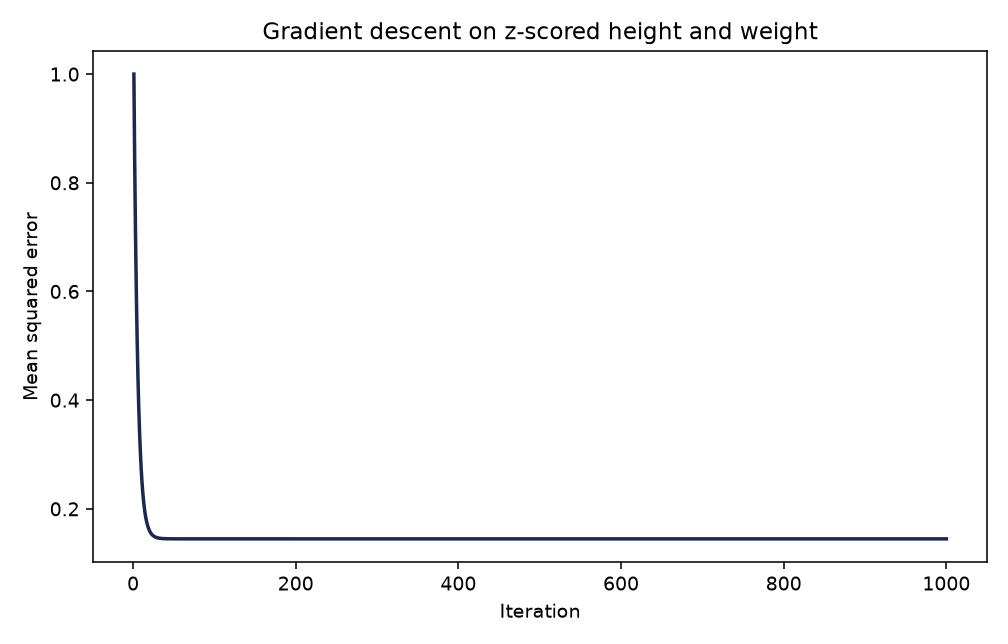

In [16]:
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.plot(range(1, iterations + 1), mseh, color="#1B2A4A", linewidth=1.8)
ax.set_xlabel("Iteration")
ax.set_ylabel("Mean squared error")
ax.set_title("Gradient descent on z-scored height and weight")
fig.tight_layout()
plot_path = figures / "gd_loss.png"
fig.savefig(plot_path, dpi=140)
plt.close(fig)
display(Image(filename=str(plot_path)))

## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time.
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal.


Note: In lab record, you can write the statements relevant to linear regression.

In [17]:
work = DF2.dropna(subset=["Traffic_Level", "Weather"]).copy()
print("rows in file:", len(DF2))
print("rows dropped (missing Traffic_Level or Weather):", len(DF2) - len(work))
print("rows kept:", len(work))
print("Traffic levels:", sorted(work["Traffic_Level"].unique()))
print("Weather levels:", sorted(work["Weather"].unique()))

rows in file: 1000
rows dropped (missing Traffic_Level or Weather): 60
rows kept: 940
Traffic levels: ['High', 'Low', 'Medium']
Weather levels: ['Clear', 'Foggy', 'Rainy', 'Snowy', 'Windy']


In [18]:
# Traffic is ordered: Low < Medium < High.
traffic_map = {"Low": 1, "Medium": 2, "High": 3}
work["Traffic_ord"] = work["Traffic_Level"].map(traffic_map)

# Weather is nominal. Clear is the reference level, so it is dropped.
weather = pd.get_dummies(work["Weather"], prefix="Weather", drop_first=False, dtype=float)
weather = weather.drop(columns=["Weather_Clear"])

X_del = pd.concat(
    [
        work[["Distance_km", "Preparation_Time_min"]].astype(float),
        work[["Traffic_ord"]].astype(float),
        weather,
    ],
    axis=1,
)
Y_del = work["Delivery_Time_min"].astype(float)
print("predictors:", list(X_del.columns))
print("X shape:", X_del.shape, "Y shape:", Y_del.shape)
X_del.head()

predictors: ['Distance_km', 'Preparation_Time_min', 'Traffic_ord', 'Weather_Foggy', 'Weather_Rainy', 'Weather_Snowy', 'Weather_Windy']
X shape: (940, 7) Y shape: (940,)


,Distance_km,Preparation_Time_min,Traffic_ord,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy
0,7.93,12.0,1.0,0.0,0.0,0.0,1.0
1,16.42,20.0,2.0,0.0,0.0,0.0,0.0
2,9.52,28.0,1.0,1.0,0.0,0.0,0.0
3,7.44,5.0,2.0,0.0,1.0,0.0,0.0
4,19.03,16.0,1.0,0.0,0.0,0.0,0.0


In [19]:
X_tr, X_te, Y_tr, Y_te = train_test_split(X_del, Y_del, test_size=0.2, random_state=67)
delivery = LinearRegression()
delivery.fit(X_tr, Y_tr)
Y_hat_del = delivery.predict(X_te)

del_mse = mean_squared_error(Y_te, Y_hat_del)
del_rmse = del_mse ** 0.5
del_mae = mean_absolute_error(Y_te, Y_hat_del)
del_r2 = r2_score(Y_te, Y_hat_del)
mean_pred = np.full(len(Y_te), float(Y_tr.mean()))
base_mae = mean_absolute_error(Y_te, mean_pred)

print("train:", len(X_tr), "test:", len(X_te))
print("test MSE (minutes^2):", round(float(del_mse), 2))
print("test RMSE (minutes):", round(float(del_rmse), 2))
print("test MAE (minutes):", round(float(del_mae), 2))
print("test R2:", round(float(del_r2), 4))
print("mean-predictor MAE (minutes):", round(float(base_mae), 2))
print("intercept (minutes):", round(float(delivery.intercept_), 2))
print("coefficients (minutes):")
for name, coef in zip(X_del.columns, delivery.coef_):
    print(f"  {name}: {coef:.2f}")

train: 752 test: 188
test MSE (minutes^2): 103.24
test RMSE (minutes): 10.16
test MAE (minutes): 6.49
test R2: 0.7684
mean-predictor MAE (minutes): 17.11
intercept (minutes): -4.88
coefficients (minutes):
  Distance_km: 3.02
  Preparation_Time_min: 1.02
  Traffic_ord: 5.69
  Weather_Foggy: 9.48
  Weather_Rainy: 5.82
  Weather_Snowy: 10.39
  Weather_Windy: 2.75


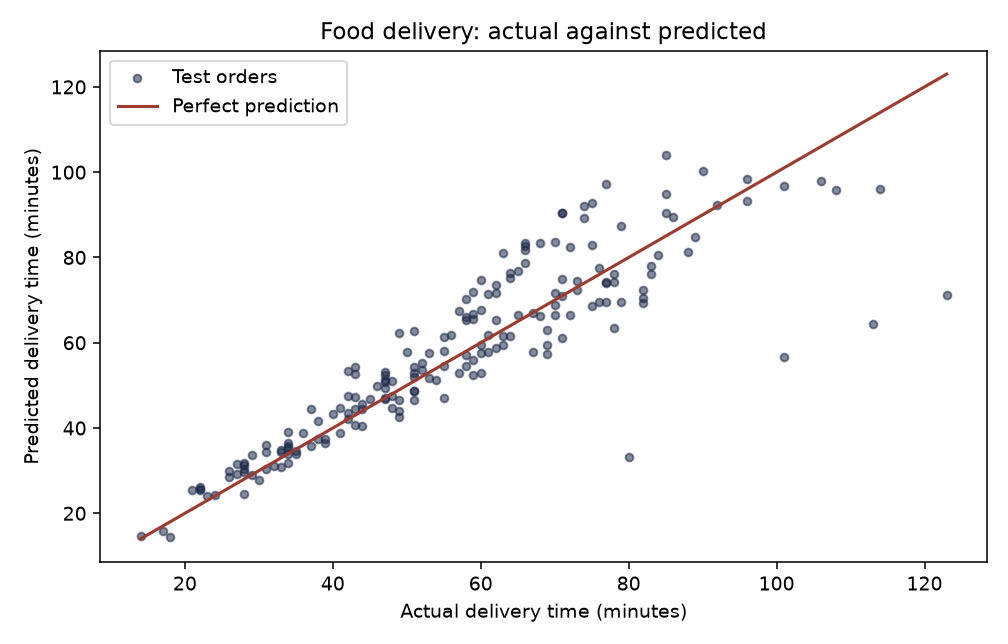

In [20]:
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.scatter(Y_te, Y_hat_del, s=16, alpha=0.55, color="#1B2A4A", label="Test orders")
lo = float(min(Y_te.min(), Y_hat_del.min()))
hi = float(max(Y_te.max(), Y_hat_del.max()))
ax.plot([lo, hi], [lo, hi], color="#9C3B2E", linewidth=1.6, label="Perfect prediction")
ax.set_xlabel("Actual delivery time (minutes)")
ax.set_ylabel("Predicted delivery time (minutes)")
ax.set_title("Food delivery: actual against predicted")
ax.legend()
fig.tight_layout()
plot_path = figures / "delivery_actual_vs_predicted.png"
fig.savefig(plot_path, dpi=140)
plt.close(fig)
display(Image(filename=str(plot_path)))

## Result

In [21]:
print("Height to weight: test R2 on the scaled target is", round(float(r2), 4))
print("The same fit misses the test weights by MAE", round(float(mean_absolute_error(y_lb, pred_lb)), 2), "pounds.")
print("Gradient descent slope", round(float(theta[1, 0]), 4), "matches the closed form.")
print("Delivery time: test MAE", round(float(del_mae), 2), "minutes, against", round(float(base_mae), 2), "minutes for the training-mean predictor.")
print("Test R2 for delivery time is", round(float(del_r2), 4))

Height to weight: test R2 on the scaled target is 0.8531
The same fit misses the test weights by MAE 9.91 pounds.
Gradient descent slope 0.9248 matches the closed form.
Delivery time: test MAE 6.49 minutes, against 17.11 minutes for the training-mean predictor.
Test R2 for delivery time is 0.7684
